# Model Interpretability & Explainability with SHAP
### Understanding What Your Model Learned


## Why Do We Need Interpretability?

You trained a model and it gets 95% accuracy. Great! But...

- **A doctor** asks: *"Why did it predict this patient has cancer?"*
- **A bank** must explain: *"Why was this loan application rejected?"* (legally required in the EU!)
etc.

A model you cannot explain is a model you cannot trust.

---

## Two Types of Explanation

| | Global | Local |
|--|--|--|
| **Question** | How does the model work overall? | Why did it predict THIS specific case? |
| **Example** | "Income is the most important feature" | "This loan was rejected because debt was too high" |
| **SHAP tool** | Summary plot, Feature importance | Waterfall plot, Force plot |

In [1]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer, fetch_california_housing
from sklearn.metrics import classification_report, r2_score
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
shap.initjs()  # enables interactive SHAP plots in the notebook
print(f"   SHAP version: {shap.__version__}")

/Users/samson.afolabi/opt/anaconda3/envs/f2m/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


   SHAP version: 0.51.0


---
## What Is a SHAP Value?

SHAP stands for **SH**apley **A**dditive ex**P**lanations.

It comes from **game theory**: imagine features as players in a team game.
The SHAP value for a feature = **how much credit does this feature deserve for the final prediction?**

### The formula (simplified)

```
prediction = base_value + SHAP(feature_1) + SHAP(feature_2) + ... + SHAP(feature_n)
```

- **base_value** = the model's average prediction (if you knew nothing about this sample)
- **positive SHAP** = this feature pushed the prediction **higher**
- **negative SHAP** = this feature pushed the prediction **lower**

### A concrete example

Predicting loan default probability:
```
Base rate:       0.20  (20% of people default on average)
+ Income low:   +0.15  (low income increases risk)
+ Debt high:    +0.12  (high debt increases risk)
+ Age young:    +0.05  (young age increases risk)
+ Good history: -0.08  (good credit history decreases risk)
= Prediction:    0.44  (44% default probability for this person)
```

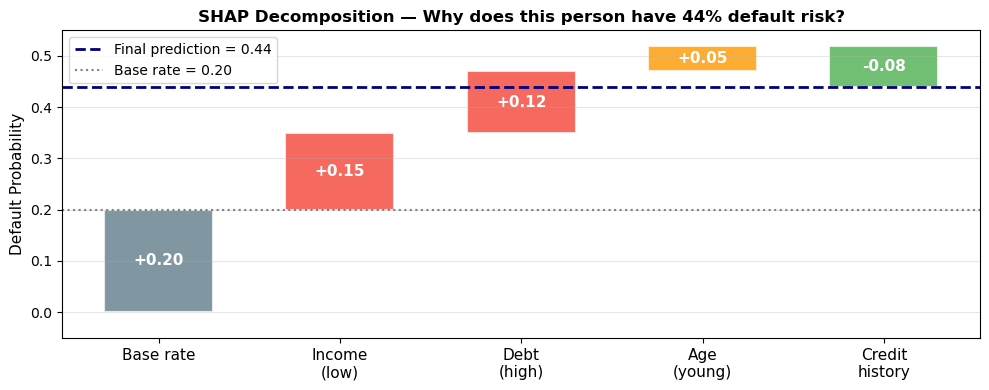

Red bars = features that INCREASE risk | Green bar = feature that DECREASES risk


In [2]:
# Visualize the SHAP concept with a manual example
fig, ax = plt.subplots(figsize=(10, 4))

categories = ['Base rate', 'Income\n(low)', 'Debt\n(high)', 'Age\n(young)', 'Credit\nhistory']
values     = [0.20,         0.15,           0.12,           0.05,           -0.08]
cumulative = np.cumsum([0] + values)
colors     = ['#607D8B', '#F44336', '#F44336', '#FF9800', '#4CAF50']

for i, (cat, val, col) in enumerate(zip(categories, values, colors)):
    bottom = cumulative[i]
    ax.bar(i, val, bottom=bottom, color=col, alpha=0.8, width=0.6, edgecolor='white', linewidth=1.5)
    sign = '+' if val >= 0 else ''
    ax.text(i, bottom + val/2, f'{sign}{val:.2f}', ha='center', va='center',
            fontsize=11, fontweight='bold', color='white')

ax.axhline(0.44, color='navy', linestyle='--', linewidth=2, label='Final prediction = 0.44')
ax.axhline(0.20, color='gray', linestyle=':', linewidth=1.5, label='Base rate = 0.20')
ax.set_xticks(range(len(categories)))
ax.set_xticklabels(categories, fontsize=11)
ax.set_ylabel('Default Probability', fontsize=11)
ax.set_title('SHAP Decomposition — Why does this person have 44% default risk?',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.set_ylim(-0.05, 0.55)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()
print("Red bars = features that INCREASE risk | Green bar = feature that DECREASES risk")

---
## Computing SHAP Values

SHAP provides different **explainers** for different model types:

| Explainer | Use for |
|-----------|--------|
| `TreeExplainer` | Random Forest, XGBoost, LightGBM (fast!) |
| `LinearExplainer` | Linear/Logistic Regression |
| `KernelExplainer` | Any model (slow but universal) |
| `DeepExplainer` | Neural networks |

## SHAP on a Regression Problem

SHAP works equally well for regression. Let's use it on California Housing prices
with a **Gradient Boosting** model.

In [3]:
housing = fetch_california_housing()
Xh = pd.DataFrame(housing.data, columns=housing.feature_names)
yh = housing.target

Xh_train, Xh_test, yh_train, yh_test = train_test_split(Xh, yh, test_size=0.2, random_state=42)

gb_model = GradientBoostingRegressor(n_estimators=200, max_depth=4, random_state=42)
gb_model.fit(Xh_train, yh_train)

r2 = r2_score(yh_test, gb_model.predict(Xh_test))
print(f"Gradient Boosting R2 on test set: {r2:.4f}")
print("Now let's explain it with SHAP...")

Gradient Boosting R2 on test set: 0.8185
Now let's explain it with SHAP...


In [4]:
explainer_gb = shap.TreeExplainer(gb_model)

# Use a sample of 500 for speed
sample_idx = np.random.choice(len(Xh_test), 500, replace=False)
X_sample = Xh_test.iloc[sample_idx]
shap_gb = explainer_gb.shap_values(X_sample)

print(f"SHAP values computed for {len(X_sample)} samples")
print(f"Shape: {shap_gb.shape}")

SHAP values computed for 500 samples
Shape: (500, 8)


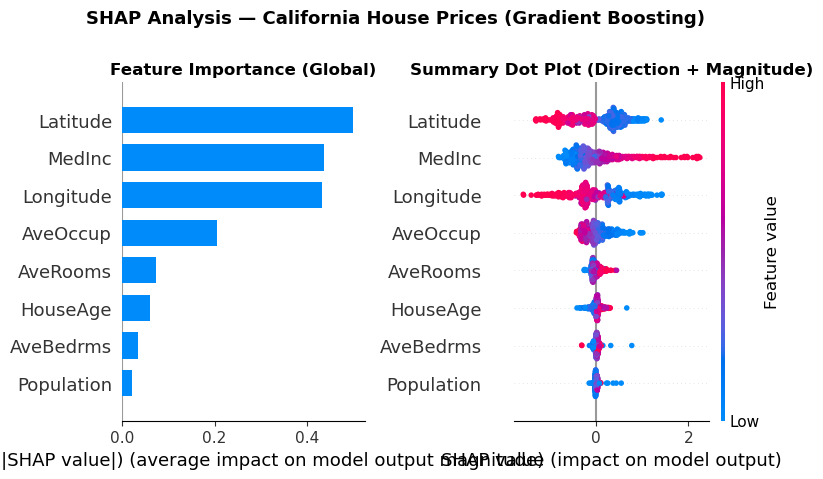

Key insights:
  MedInc   : High income areas have significantly higher house prices
  Latitude : More southern (lower latitude) locations tend to be higher priced
  AveOccup : High occupancy pushes prices down


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plt.sca(axes[0])
shap.summary_plot(shap_gb, X_sample, plot_type='bar', show=False)
axes[0].set_title("Feature Importance (Global)", fontsize=12, fontweight='bold')

plt.sca(axes[1])
shap.summary_plot(shap_gb, X_sample, show=False)
axes[1].set_title("Summary Dot Plot (Direction + Magnitude)", fontsize=12, fontweight='bold')

plt.suptitle("SHAP Analysis — California House Prices (Gradient Boosting)",
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print("Key insights:")
print("  MedInc   : High income areas have significantly higher house prices")
print("  Latitude : More southern (lower latitude) locations tend to be higher priced")
print("  AveOccup : High occupancy pushes prices down")

In [6]:
print("Why SHAP is better than built-in importance:")
print("  SHAP shows direction (positive or negative effect)")
print("  SHAP is consistent across different model types")
print("  SHAP provides LOCAL (per-sample) explanations")

Why SHAP is better than built-in importance:
  SHAP shows direction (positive or negative effect)
  SHAP is consistent across different model types
  SHAP provides LOCAL (per-sample) explanations
